## E-Commerce Returns: EDA & Visualization Phase

- BSIT 3A-G1 Group 1
- Acero, Eldrei Tyler
- Adriano, Arianne Denisse
- Cabataña, Jocky King
- Elopre, Ross Anthony
- Naval, Cyrhyl Kurt
- Pelayo, Danielle Griz
- Zaldivar, Jaen Royce


This section visualizes the **cleaned** dataset to understand what drives product returns and to show how well the final model performs. Each chart has a short business insight underneath.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
PALETTE = {'Kept': '#4C9F70', 'Returned': '#D1495B'}

In [2]:
df = pd.read_csv('./datasets/processed/ecommerce_returns_clean.csv', parse_dates=['Date'])
df['Returned'] = (df['Return Status'] == 'Returned').astype(int)   # 1 = returned, used for return-rate charts
df['Order Month'] = df['Date'].dt.month
df['Is Weekend'] = (df['Date'].dt.dayofweek >= 5).astype(int)      # real weekend (Sat/Sun)

print(df.shape)
df.head()

(10000, 17)


,Order ID,Date,Time of Purchase,Customer Age,Customer Gender,Device Used,Product Category,Total Order Value,Discount Applied,Payment Method,Shipping Type,Customer Rating,Return Status,Rating Missing,Returned,Order Month,Is Weekend
0,ORD-100000,2024-10-16,Morning,56,Female,Mobile,Sports,4144.83,0.42,Credit Card,Standard,2.0,Kept,0,0,10,0
1,ORD-100001,2023-04-25,Morning,69,Male,Mobile,Clothing,21436.04,0.01,E-Wallet,Standard,3.0,Returned,0,1,4,0
2,ORD-100002,2023-01-26,Midnight,46,Male,Mobile,Home,15655.16,0.10,Cash on Delivery,Express,4.0,Returned,1,1,1,0
3,ORD-100003,2025-01-29,Evening,32,Female,Desktop,Electronics,12566.34,0.44,E-Wallet,Standard,3.0,Kept,0,0,1,0
4,ORD-100004,2023-10-09,Afternoon,60,Male,Mobile,Home,23072.84,0.49,E-Wallet,Standard,4.0,Kept,0,0,10,0


### Chart 1: Overall Return Status

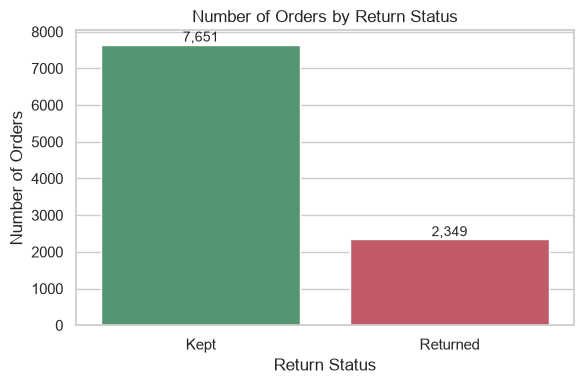

Overall return rate: 23.5%


In [3]:
counts = df['Return Status'].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Return Status', order=counts.index, palette=PALETTE, hue='Return Status', legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
ax.set_title('Number of Orders by Return Status')
ax.set_xlabel('Return Status')
ax.set_ylabel('Number of Orders')
plt.tight_layout(); plt.show()
print(f"Overall return rate: {df['Returned'].mean():.1%}")

**Business insight:** _(write after running: what is the overall return rate, and is the data imbalanced?)_

### Chart 2: Return Rate by Product Category

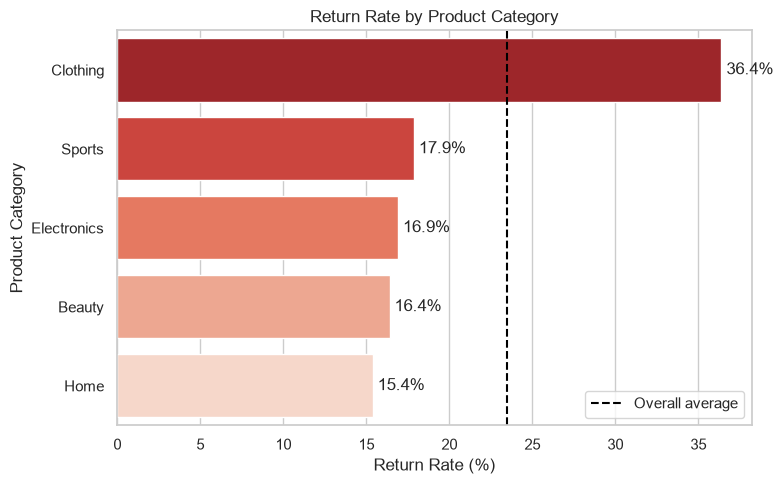

In [4]:
rate = df.groupby('Product Category')['Returned'].mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=rate.values, y=rate.index, palette='Reds_r', hue=rate.index, legend=False, ax=ax)
ax.axvline(df['Returned'].mean()*100, color='black', ls='--', label='Overall average')
for i, v in enumerate(rate.values):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center')
ax.set_title('Return Rate by Product Category')
ax.set_xlabel('Return Rate (%)')
ax.set_ylabel('Product Category')
ax.legend()
plt.tight_layout(); plt.show()

**Business insight:** _(which categories return the most, and which are above the dashed average line?)_

### Chart 3: Return Rate by Shipping Type and Payment Method

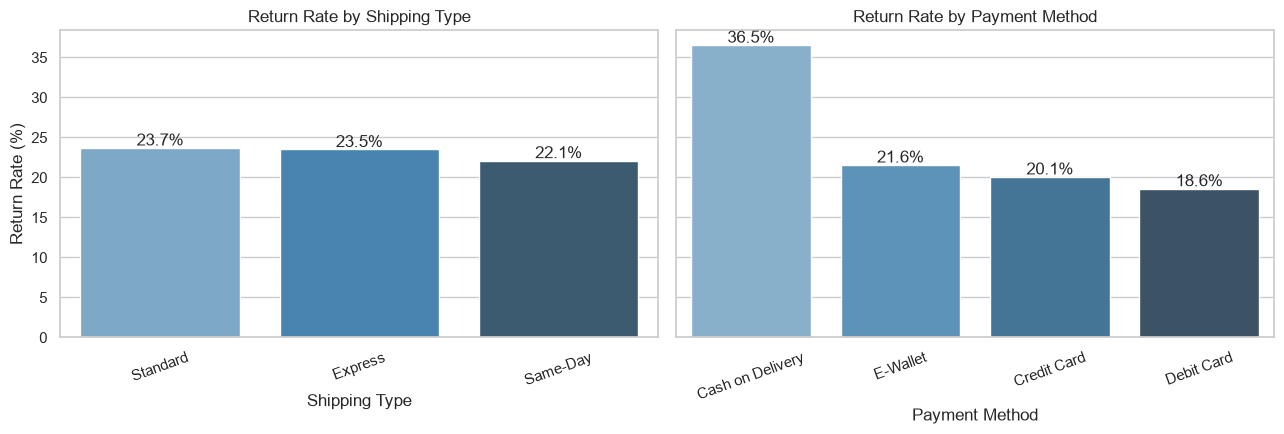

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, col in zip(axes, ['Shipping Type', 'Payment Method']):
    r = df.groupby(col)['Returned'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=r.index, y=r.values, palette='Blues_d', hue=r.index, legend=False, ax=ax)
    for i, v in enumerate(r.values):
        ax.text(i, v + 0.3, f'{v:.1f}%', ha='center')
    ax.set_title(f'Return Rate by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Return Rate (%)')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Business insight:** _(does faster shipping or a certain payment method relate to more returns?)_

### Chart 4: Discount Applied vs Return Status

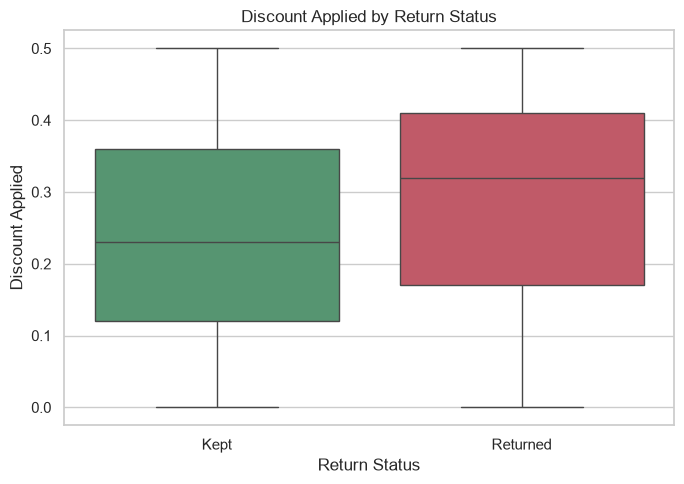

                count  mean   std  min   25%   50%   75%  max
Return Status                                                
Kept           7651.0  0.24  0.14  0.0  0.12  0.23  0.36  0.5
Returned       2349.0  0.29  0.14  0.0  0.17  0.32  0.41  0.5


In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x='Return Status', y='Discount Applied', order=['Kept', 'Returned'],
            palette=PALETTE, hue='Return Status', legend=False, ax=ax)
ax.set_title('Discount Applied by Return Status')
ax.set_xlabel('Return Status')
ax.set_ylabel('Discount Applied')
plt.tight_layout(); plt.show()
print(df.groupby('Return Status')['Discount Applied'].describe().round(2))

**Business insight:** _(do heavily discounted orders get returned more?)_

### Chart 5: Customer Rating vs Return Status

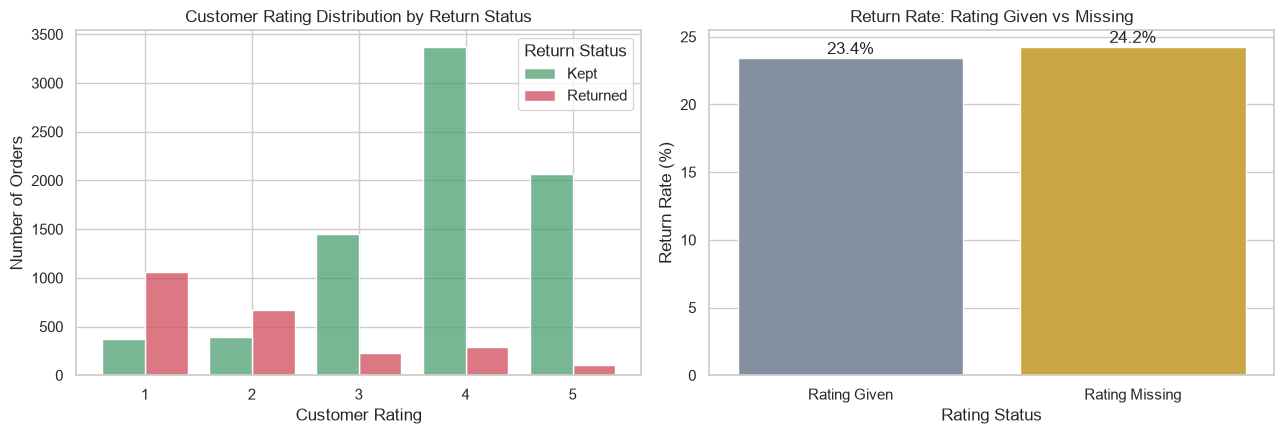

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data=df, x='Customer Rating', hue='Return Status', multiple='dodge', discrete=True,
             palette=PALETTE, shrink=0.8, ax=axes[0])
axes[0].set_title('Customer Rating Distribution by Return Status')
axes[0].set_xlabel('Customer Rating')
axes[0].set_ylabel('Number of Orders')

r = df.groupby('Rating Missing')['Returned'].mean() * 100
r.index = r.index.map({0: 'Rating Given', 1: 'Rating Missing'})
sns.barplot(x=r.index, y=r.values, palette=['#7F8FA6', '#E1B12C'], hue=r.index, legend=False, ax=axes[1])
for i, v in enumerate(r.values):
    axes[1].text(i, v + 0.3, f'{v:.1f}%', ha='center')
axes[1].set_title('Return Rate: Rating Given vs Missing')
axes[1].set_xlabel('Rating Status')
axes[1].set_ylabel('Return Rate (%)')
plt.tight_layout(); plt.show()

**Business insight:** _(are low ratings tied to returns? Is a missing rating itself a signal?)_

### Chart 6: Total Order Value by Return Status

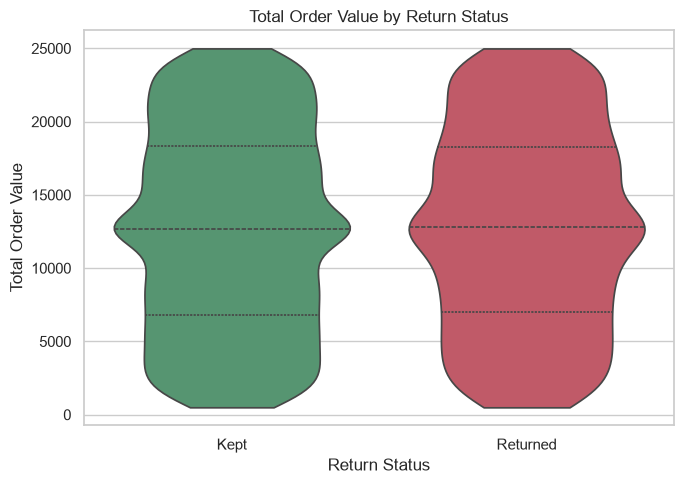

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.violinplot(data=df, x='Return Status', y='Total Order Value', order=['Kept', 'Returned'],
               palette=PALETTE, hue='Return Status', legend=False, inner='quartile', cut=0, ax=ax)
ax.set_title('Total Order Value by Return Status')
ax.set_xlabel('Return Status')
ax.set_ylabel('Total Order Value')
plt.tight_layout(); plt.show()

**Business insight:** _(are returned orders more expensive or cheaper than kept ones?)_

### Chart 7: Monthly Return Rate Trend

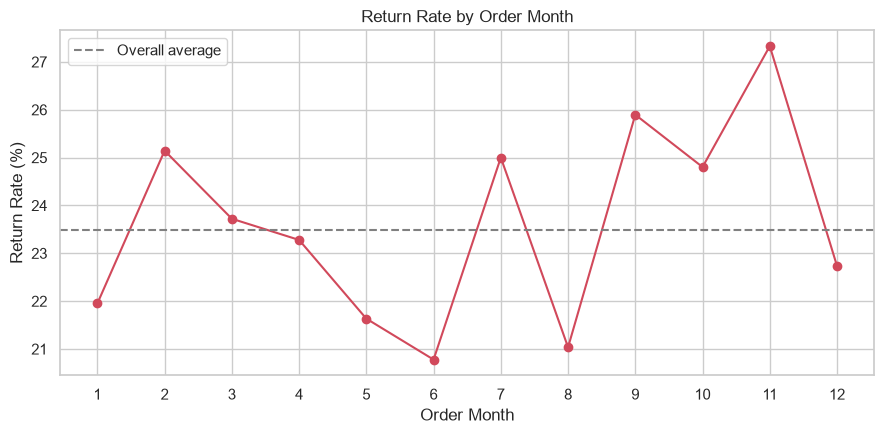

In [9]:
m = df.groupby('Order Month')['Returned'].mean() * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(m.index, m.values, marker='o', color='#D1495B')
ax.axhline(df['Returned'].mean()*100, color='gray', ls='--', label='Overall average')
ax.set_xticks(range(1, 13))
ax.set_title('Return Rate by Order Month')
ax.set_xlabel('Order Month')
ax.set_ylabel('Return Rate (%)')
ax.legend()
plt.tight_layout(); plt.show()

**Business insight:** _(any seasonal spikes in returns?)_

### Chart 8: Correlation Heatmap

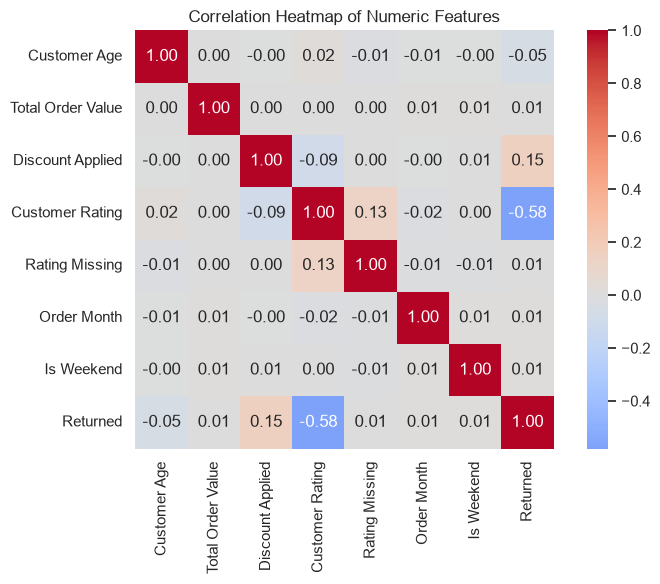

In [10]:
num_cols = ['Customer Age', 'Total Order Value', 'Discount Applied', 'Customer Rating',
            'Rating Missing', 'Order Month', 'Is Weekend', 'Returned']
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, ax=ax)
ax.set_title('Correlation Heatmap of Numeric Features')
plt.tight_layout(); plt.show()

**Business insight:** _(which features have the strongest correlation with `Returned`? Note that weak linear correlation does not rule out non-linear effects.)_

## Model Result Visuals

These charts use the same preparation and split as `03_MODELING.ipynb` (60/20/20, `random_state=42`, stratified) and the Random Forest settings from that notebook, so the results match. The only change is that `is_weekend` here uses the real day of week.

In [11]:
d = df.drop(columns=['Order ID', 'Date', 'Returned'], errors='ignore').copy()
d.columns = d.columns.str.lower().str.replace(' ', '_')
d['return_status'] = d['return_status'].map({'Returned': 1, 'Kept': 0})
d['shipping_type'] = d['shipping_type'].map({'Standard': 0, 'Express': 1, 'Same-Day': 2})
cat_cols = ['payment_method', 'product_category', 'device_used', 'customer_gender', 'time_of_purchase']
d = pd.get_dummies(d, columns=[c for c in cat_cols if c in d.columns], drop_first=True, dtype=int)

X = d.drop('return_status', axis=1)
y = d['return_status']
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=6767, stratify=y_temp)

rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=67)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

### Chart 9: Confusion Matrix (Random Forest, Test Set)

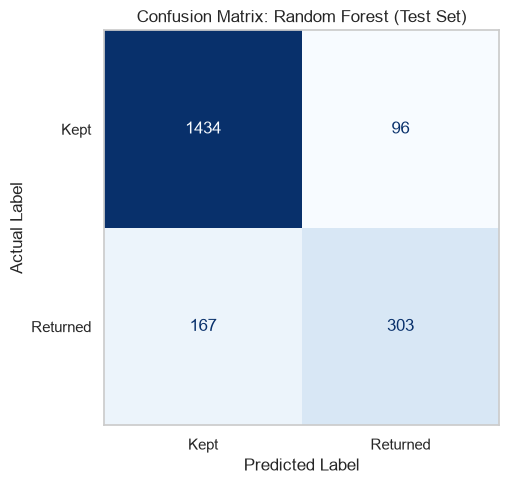

In [12]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=['Kept', 'Returned']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix: Random Forest (Test Set)')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('Actual Label')
ax.grid(False)
plt.tight_layout(); plt.show()

**Business insight:** _(how many returns did the model catch vs miss? Which error costs the business more?)_

### Chart 10: Feature Importance (Top 10)

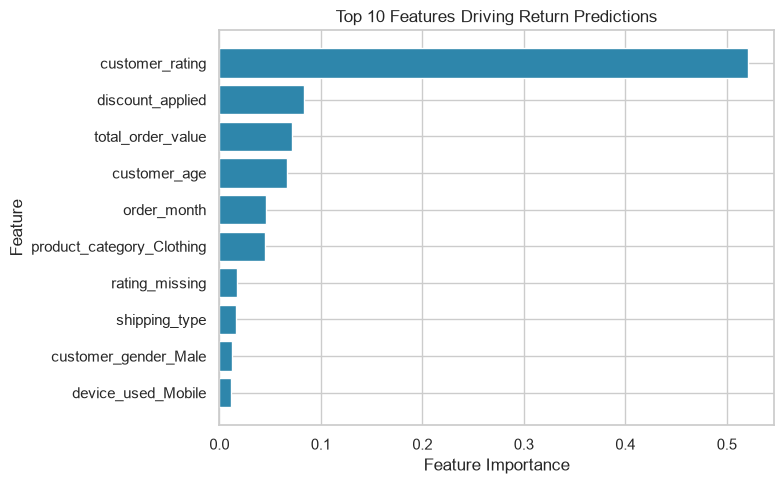

In [13]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color='#2E86AB')
ax.set_title('Top 10 Features Driving Return Predictions')
ax.set_xlabel('Feature Importance')
ax.set_ylabel('Feature')
plt.tight_layout(); plt.show()

**Business insight:** _(which factors should management act on first?)_